In [8]:
import easyocr
import cv2
import numpy as np
import matplotlib.pyplot as plt
import re


In [46]:
from easyocr import Reader

In [47]:
reader = Reader(['en'], gpu=True,quantize=True)

In [7]:
def enhance_image(img):
            # Convert to grayscale if not already
            if len(img.shape) == 3:
                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            else:
                gray = img
            clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
            enhanced = clahe.apply(gray)
            
            # Apply thresholding
            _, binary = cv2.threshold(enhanced, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
            
            # Denoise
            kernel = np.ones((2,2), np.uint8)
            binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
            
            # Invert back for OCR
            binary = cv2.bitwise_not(binary)
            
            return binary

In [6]:
def extract_points_and_attempts(image , save=False):    
        # Crop the relevant parts of the image
        height, width, _ = image.shape
        cropped_points = image[int(height*0.08):int(height*0.13), int(width*0.879):int(width*0.923)]
        cropped_attempts = image[int(height*0.14):int(height*0.17), int(width*0.78):int(width*0.8)]
        
        # if save:
        #     cv2.imwrite("cropped_points.png" , cropped_points)
        #     cv2.imwrite("cropped_attempts.png" , cropped_attempts)
        
        
        
        # Process points image
        enhanced_points = enhance_image(cropped_points)
        enhanced_points = cv2.resize(enhanced_points, (0, 0), fx=2, fy=2)
        result_points = reader.readtext(enhanced_points)
        
        # Process attempts image
        enhanced_attempts = enhance_image(cropped_attempts)
        enhanced_attempts = cv2.resize(enhanced_attempts, (0, 0), fx=2, fy=2)
        result_attempts = reader.readtext(enhanced_attempts)
        
        # Extract points
        points = None
        if len(result_points) > 0:
            points_text = result_points[0][1]
            points_numbers = re.findall(r'\d+', points_text)
            points = ''.join(points_numbers) if points_numbers else None
        
        # Extract attempts
        attempts = None
        if len(result_attempts) > 0:
            attempts_text = result_attempts[0][1]
            attempts_numbers = re.findall(r'\d+', attempts_text)
            attempts = ''.join(attempts_numbers) if attempts_numbers else None
        
        return {
            'points': points,
            'attempts': attempts,
            'raw_points': result_points[0][1] if len(result_points) > 0 else None,
            'raw_attempts': result_attempts[0][1] if len(result_attempts) > 0 else None
        }

In [21]:
img = cv2.imread('frame.png')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)



In [12]:
import pytesseract
import cv2
import numpy as np
from PIL import Image
import re

# Explicitly set the path to tesseract.exe
pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'

# Load image with OpenCV
image = cv2.imread('cc.png')

# Step 1: Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Step 2: Apply Gaussian blur to reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Step 3: Apply adaptive thresholding to binarize (enhance contrast)
thresh = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
                              cv2.THRESH_BINARY, 11, 2)

# Step 4: (Optional) Resize image to improve OCR accuracy
scale_percent = 150  # Increase size by 150%
width = int(thresh.shape[1] * scale_percent / 100)
height = int(thresh.shape[0] * scale_percent / 100)
resized = cv2.resize(thresh, (width, height), interpolation=cv2.INTER_LINEAR)

# Save or use preprocessed image
cv2.imwrite('preprocessed_cc.png', resized)  # Optional: Save to inspect
image_pil = Image.fromarray(resized)  # Convert to PIL Image for pytesseract

# Configure Tesseract to detect only numbers
custom_config = r'--oem 3 --psm 6 -c tessedit_char_whitelist=0123456789'
text = pytesseract.image_to_string(image_pil, config=custom_config)

# Extract numbers
numbers = re.findall(r'\d+', text)
print('Extracted numbers:', numbers)
print(''.join(numbers))

Extracted numbers: []



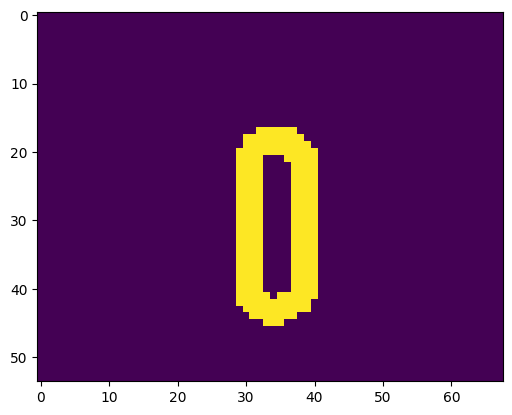

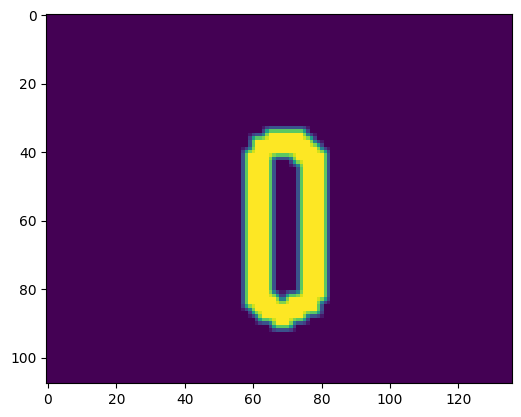

Text: 0, Confidence: 96%
Extracted numbers: ['0']
0


In [13]:
import pytesseract
from PIL import Image
import re
import cv2
# Explicitly set the path to tesseract.exe
pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'

# Load image
img = cv2.imread('ee.png')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
# img = img[0:int(img.shape[0]*0.2), int(img.shape[1]*0.8):int(img.shape[1]*0.9)]
# crop image from right and left 10%
img = img[:, int(img.shape[1]*0.1):int(img.shape[1]*0.9)]
enhanced_points = enhance_image(img)
plt.imshow(enhanced_points)
plt.show()

enhanced_points = cv2.resize(enhanced_points, (0, 0), fx=2, fy=2)
plt.imshow(enhanced_points)
plt.show()


# image = Image.open('cc.png')

# Configure Tesseract to detect only numbers
custom_config = r'--oem 3 --psm 6 -c tessedit_char_whitelist=0123456789'
# text = pytesseract.image_to_string(enhanced_points, config=custom_config)

# # Extract numbers
# numbers = re.findall(r'\d+', text)
# print('Extracted numbers:', numbers)
# print(''.join(numbers))
# Replace the image_to_string line with this
data = pytesseract.image_to_data(enhanced_points, config=custom_config, output_type=pytesseract.Output.DICT)

# Print confidence for each detected text
for i in range(len(data['text'])):
    if data['text'][i].strip() != '':
        confidence = data['conf'][i]
        print(f"Text: {data['text'][i]}, Confidence: {confidence}%")

# You can still extract numbers as before
text = ' '.join(data['text'])
numbers = re.findall(r'\d+', text)
print('Extracted numbers:', numbers)
print(''.join(numbers))

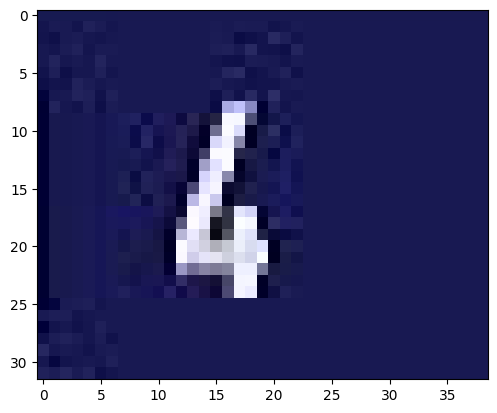

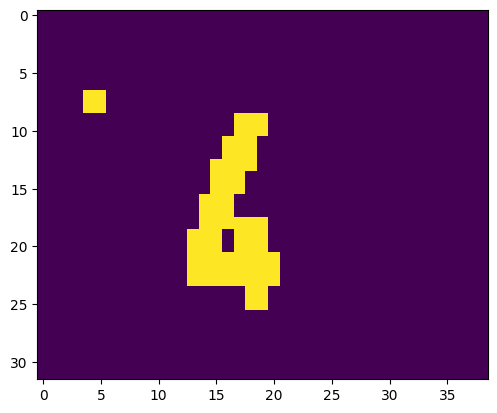

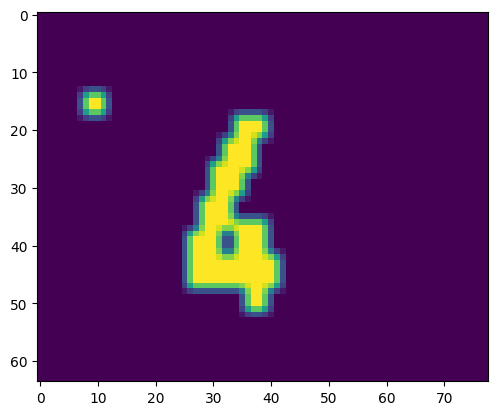

[]
None


In [5]:
imgocr = cv2.imread('cc.png')
imgocr = cv2.cvtColor(imgocr, cv2.COLOR_BGR2RGB)
plt.imshow(imgocr)
plt.show()
enhanced_points = enhance_image(imgocr)
plt.imshow(enhanced_points)
plt.show()

enhanced_points = cv2.resize(enhanced_points, (0, 0), fx=2, fy=2)
plt.imshow(enhanced_points)
plt.show()
result_points = reader.readtext(imgocr,threshold=0.01)
print(result_points)
points = None
if len(result_points) > 0:
    points_text = result_points[0][1]
    points_numbers = re.findall(r'\d+', points_text)
    points = ''.join(points_numbers) if points_numbers else None
print(points)

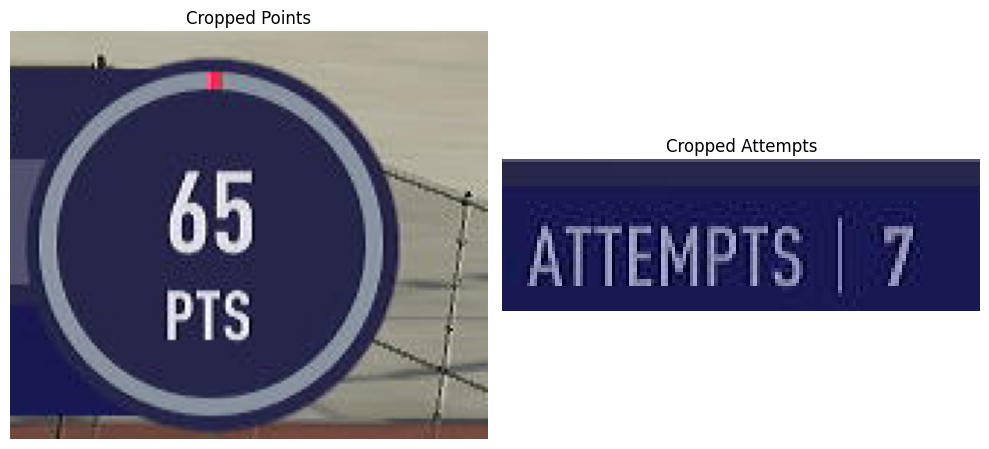

In [40]:
height, width, _ = img.shape
cropped_points = img[int(height*0.05):int(height*0.18), int(width*0.865):int(width*0.95)]
cropped_attempts = img[int(height*0.13):int(height*0.17), int(width*0.73):int(width*0.8)]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cropped_points)
plt.title("Cropped Points")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cropped_attempts)
plt.title("Cropped Attempts")
plt.axis('off')
plt.tight_layout()
plt.show()

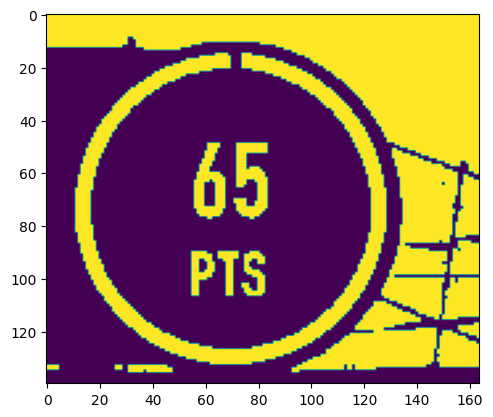

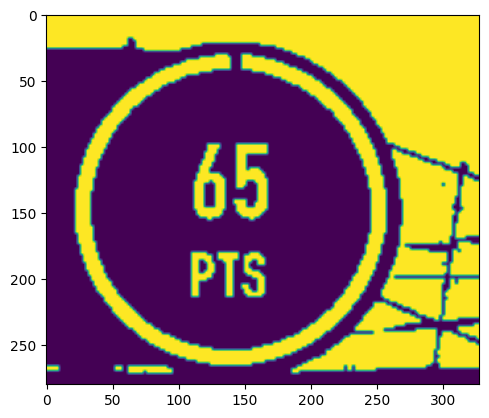

[([[100, 88], [180, 88], [180, 164], [100, 164]], '65', 0.9998440602219226), ([[102, 174], [174, 174], [174, 222], [102, 222]], 'PTS', 0.9977873814260002)]
Points: 65
7
Text: '', Confidence: -1%
Extracted text: 


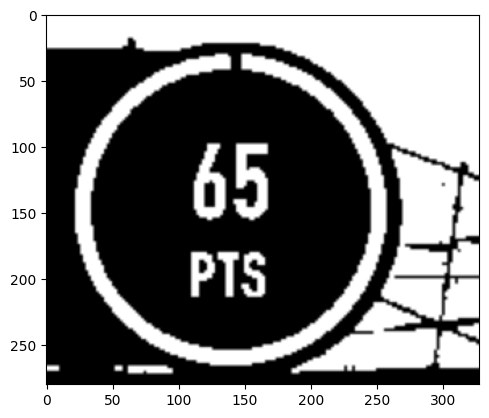

In [52]:
import pytesseract
from PIL import Image
import re
import cv2
# Explicitly set the path to tesseract.exe
pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'

enhanced_points = enhance_image(cropped_points)
plt.imshow(enhanced_points)
plt.show()

enhanced_points = cv2.resize(enhanced_points, (0, 0), fx=2, fy=2)
plt.imshow(enhanced_points)
plt.show()
# custom_config = r'--oem 3 --psm 6 -c tessedit_char_whitelist=0123456789'
# data = pytesseract.image_to_data(enhanced_points, config=custom_config, output_type=pytesseract.Output.DICT)
custom_config = r'--oem 3 --psm 6'
data = pytesseract.image_to_data(enhanced_points, config=custom_config, output_type=pytesseract.Output.DICT)
result_points = reader.readtext(enhanced_points)
print(result_points)
# for each result choose the result that have all digits ignore PTS if detected and choose the other even if it has char make it integer only
points = None
if result_points:
    for result in result_points:
        text = result[1]
        if re.fullmatch(r'\d+', text):  # Check if the text contains only digits
            points = text
            break
# for result in result_points:
#     text = result[1]
#     if re.fullmatch(r'\d+', text):  # Check if the text contains only digits
#         points = text
#         break
print('Points:', points)





enhanced_attempts = enhance_image(cropped_attempts)
enhanced_attempts = cv2.resize(enhanced_attempts, (0, 0), fx=2, fy=2)
result_att = reader.readtext(enhanced_attempts)
attempts = None
if result_att:
    for result in result_att:
        text = result[1]
        if re.fullmatch(r'\d+', text):  # Check if the text contains only digits
            attempts = text
            break 
print(attempts)
# Print all detections, including low confidence
for i in range(len(data['text'])):
    text = data['text'][i]
    confidence = data['conf'][i]
    print(f"Text: '{text}', Confidence: {confidence}%")

# Optional: Extract all text as a single string
text = ' '.join(data['text'])
print('Extracted text:', text)

# Optional: Visualize detections with bounding boxes
img_with_boxes = enhanced_points.copy()
for i in range(len(data['text'])):
    if data['conf'][i] > 0:  # Only draw boxes for non-negative confidence
        (x, y, w, h) = (data['left'][i], data['top'][i], data['width'][i], data['height'][i])
        cv2.rectangle(img_with_boxes, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(img_with_boxes, f"{data['text'][i]} ({data['conf'][i]}%)", (x, y - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
plt.imshow(cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB))
plt.show()


In [49]:
# predict = extract_points_and_attempts(img, save=True
predict = extract_points_and_attempts(img, save=True)
print("Raw Points: ", predict['raw_points'])
print("Predicted Points: ", predict['points'])
print("Predicted Attempts: ", predict['attempts'])

Raw Points:  65
Predicted Points:  65
Predicted Attempts:  7
